# FFT-Workflow

[&larr; Einführung](01_FFT.ipynb)

Der Ablauf der Berechnung des Frequenzspektrums ist immer gleich, d. h. die folgenden Schritte werden nacheinander durchgeführt:

1. Zeitsignal `y` bereitstellen und Abtastfrequenz `fs` sowie Sampleanzahl `N` bestimmen
2. Fensterfunktion anwenden:
   - Fensterfunktion erzeugen `w = signal.windows.get_window('...', N)`
   - Fensterfunktion anwenden (Offset beachten) `y_w = w * (y - y.mean()) + y.mean()`
3. FFT berechnen mittels `Y = fft.rfft(y_w)/N` und anschliessend Amplituden korrekt skalieren
   - Amplituden bestimmen `A = abs(Y)`
   - Amplituden skalieren `A[1:] *= 2`
4. Frequenzachse erzeugen mittels `f = fft.rfftfreq(N, 1/fs)`
5. Amplitudenspektrum grafisch darstellen

☝🏼 Möchte man keine Fensterfunktion verwenden, den obigen Workflow aber gleich lassen, so kann das Fenster `boxcar` verwendet werden (gleichbedeutend mit keiner Fensterung).

---

## Beispiel

Anhand eines Beispieldatensatzes (`data/messung.csv`) wollen wir den FFT-Workflow durchgehen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft, signal

### 1. Zeitsignal bereitstellen und Abtastfrequenz bzw. Sampleanzahl bestimmen

In der Regel stammt das Signal aus einer Messung und liegt in Form eines Textfiles vor. Die Informationen zur Abtastung sind entweder direkt gegeben (Abtastfrequenz $f_S$ oder Zeitschrittweite $\Delta t$) oder müssen aus dem Zeitschritt-Array ermittelt werden.

In [2]:
data = np.loadtxt('data/messung.csv', delimiter=';', skiprows=1)
t = data[:,0]  # Zeitschritte
y = data[:,1]  # Messignal
N = len(t)  # Sampleanzahl
fs = 1 / (t[1]-t[0])  # Abtastfrequenz (alternativ: fs = 1 / np.diff(t)[0])

### 2. Fensterfunktion anwenden

Da das Signal i. Allg. nicht exakt periodisch ist, wird üblicherweise vor der Fouriertransformation eine Fensterung durchgeführt. Dafür stehen verschiedene Fensterfunktionen zur Verfügung (z. B. `hamming`, `hann`, `tukey`, ...). Die verschiedenen Fenster unterscheiden sich durch geringe Details, haben aber alle den Effekt, den negativen Einfluss der Nicht-Periodizität des Signals zu verringern.

In [3]:
# Fenstertyp 'boxcar' ist gleichbedeutend mit keiner Fensterung
w = signal.windows.get_window('tukey', N)  # Fenster erzeugen
y_w = w * (y - y.mean()) + y.mean()  # Fensterfunktion anwenden (Offset für Fensterung entfernen)

### 3. FFT berechnen und Amplituden korrekt skalieren

Für die Berechnung der Fouriertransformation wird die Funktion `rfft()` verwendet. Diese gibt die Anteile der positiven Frequenzen zurück und deshalb müssen die Amplituden (ausser der Gleichanteil) anschliessend noch verdoppelt werden.

☝🏼 Erklärung: Die wahre (gesamte) Amplitude ist jeweils zur Hälfte auf die positive und negative Frequenz aufgeteilt und durch die Verdopplung wird sozusagen der Anteil der negativen Frequenzen auf die positive Seite gebracht. Für den DC-Anteil (0 Hz) gibt es kein negatives Pendant, d. h. die Amplitude bei 0 Hz (`A[0]`) darf nicht verdoppelt werden.

In [4]:
Y = fft.rfft(y_w)/N  # Frequenzspektrum berechnen
A = abs(Y)  # Amplituden
A[1:] *= 2  # Amplituden skalieren (alle Amplituden ausser Gleichanteil müssen verdoppelt werden)

### 4. Frequenzachse erzeugen

Die Frequenzachse läuft von 0 Hz (Gleichanteil oder DC-Anteil) bis zur Frequenz $f_S/2$ (*Nyquist*-Frequenz). Die Schrittweite $\Delta f$ entspricht $1/t_{meas} = f_S/N$. Die Frequenzachse könnte manuell erstellt werden, doch der Einfachheit halber wird die Funktion `rfftfreq()` verwendet.

In [5]:
f = fft.rfftfreq(N, 1/fs)  # Frequenzachse erstellen

### 5. Spektrum darstellen

Die grafische Darstellung des Amplitudenspektrums erfolgt mit den bekannten Funktionen von Matplotlib.

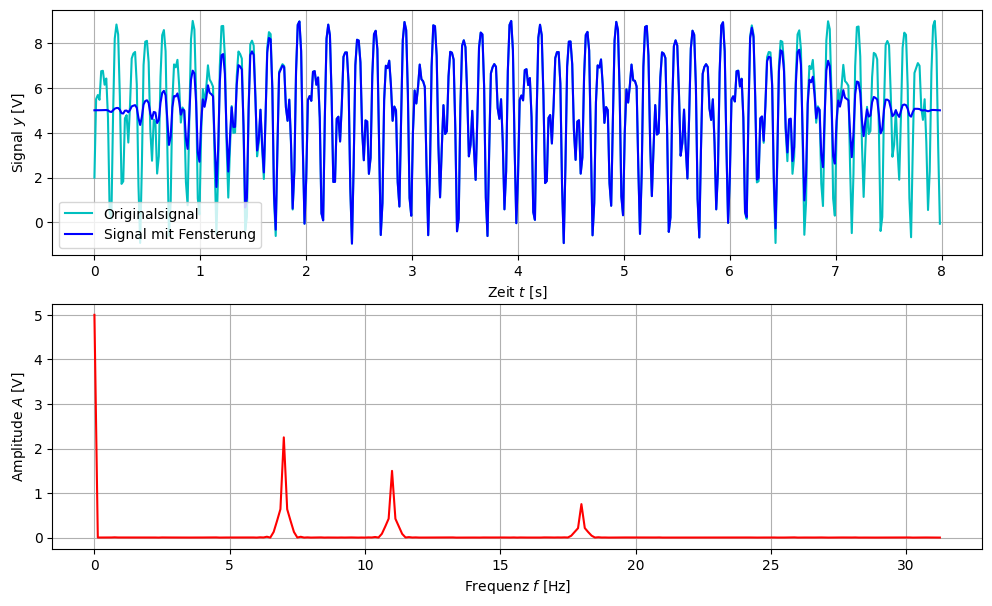

In [6]:
fig, axs = plt.subplots(nrows=2, figsize=(12,7))
axs[0].plot(t, y, 'c', label='Originalsignal')  # Zeitsignal (original)
axs[0].plot(t, y_w, 'b', label='Signal mit Fensterung')  # Zeitsignal (gefenstert)
axs[0].set_xlabel('Zeit $t$ [s]')
axs[0].set_ylabel('Signal $y$ [V]')
axs[0].legend()
axs[0].grid()
axs[1].plot(f, A, 'r-', label='Spektrum')  # Amplitudenspektrum
axs[1].set_xlabel('Frequenz $f$ [Hz]')
axs[1].set_ylabel('Amplitude $A$ [V]')
axs[1].grid()
plt.show()

☝🏼 Das Spektrum wird häufig mit logarithmischer Amplitudenachse (oder in dB) dargestellt, damit die z. T. grossen Unterschiede in der Höhe der Peaks besser erkannt werden können. Wenn ein sehr grosser Frequenzbereich vorliegt (mehrere Grössenordnungen) kann auch eine logarithmische Frequenzachse sinnvoll sein.